# Method explanation

How the front clusters are built, step by step, on the run behind
`nemi_out_tomato_k100g100_tau0.5_v3_fronts.parquet`.

10 UMAP members, 2,303,529 fronts, 3 dimensions


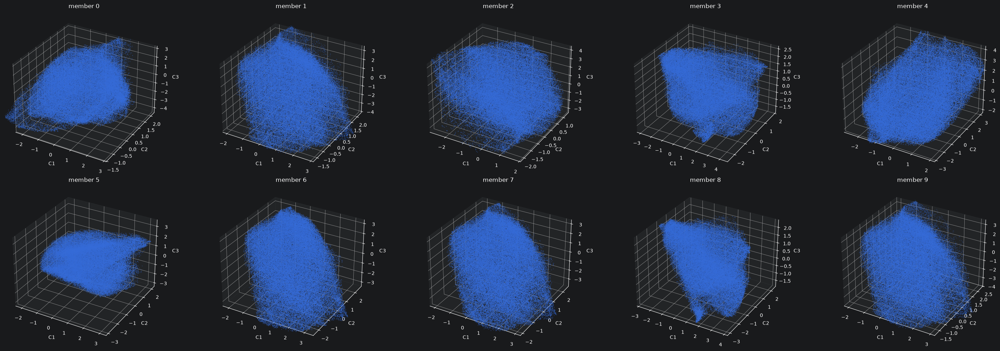

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.spatial import cKDTree

from visualization.visualization import vis_dim_redux_list

NEMI_FILE = "nemi_out_tomato_k100g100_tau0.5_v3.npz"   # the run the working parquet was exported from
N_SHOW = 100_000         # fronts drawn per panel; the same fronts in every panel
ALPHA = 0.9

embeddings = np.load(NEMI_FILE)["embeddings"]        # (members, fronts, 3)
n_members, n_fronts, dims = embeddings.shape
print(f"{n_members} UMAP members, {n_fronts:,} fronts, {dims} dimensions")

rows = np.sort(np.random.default_rng(0).choice(n_fronts, N_SHOW, replace=False))
vis_dim_redux_list(embeddings[:, rows], dims=dims, alpha=ALPHA, n_cols=5,
                   titles=[f"member {m}" for m in range(n_members)])

## Density landscape of each member

Each member's 3-D embedding is projected onto its two principal axes, and every front is raised to its log-DTM
density in that plane.  ToMATo works on the 3-D density, so this is a picture of the peaks and saddles it merges,
not the density it is given.

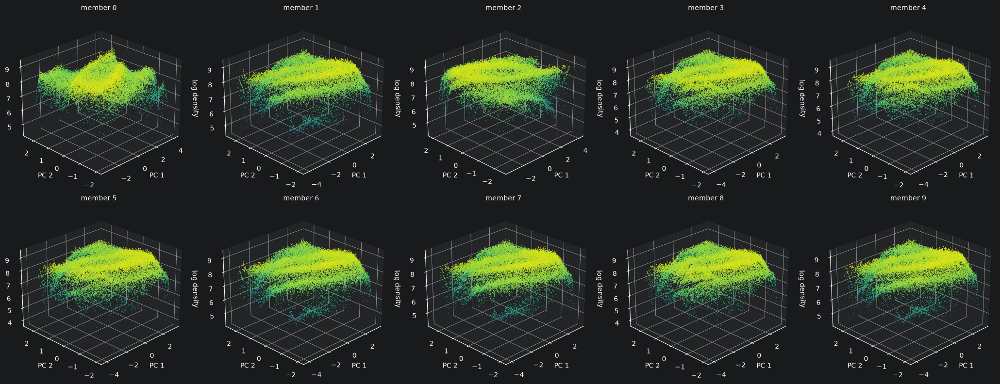

In [2]:
K_DENS = 100            # neighbors in the density estimate, as in the final ToMATo run
N_DENSITY = 30_000      # fronts drawn per panel
PCT = (0.5, 99.5)       # fronts outside this percentile range of either projected axis are not drawn


def project_2d(E):
    """E on its two principal axes: the plane of the member's largest spread."""
    E = E - E.mean(axis=0)
    _, vectors = np.linalg.eigh(np.cov(E.T))
    return E @ vectors[:, ::-1][:, :2]


def log_dtm(P, rows, k):
    """Log-DTM density of P[rows] among every front in P: -(dim / 2) log of the mean squared distance to the k
    nearest fronts, the estimate tomato_nemi makes, with dim the number of columns of P."""
    dist = cKDTree(P).query(P[rows], k=k + 1, workers=-1)[0][:, 1:]
    return -(P.shape[1] / 2) * np.log(np.maximum(np.mean(dist ** 2, axis=1), 1e-24))


shown = np.sort(np.random.default_rng(1).choice(n_fronts, N_DENSITY, replace=False))
n_cols = 5
n_rows = -(-n_members // n_cols)
fig = plt.figure(figsize=(4.2 * n_cols, 4 * n_rows))
for m in range(n_members):
    P = project_2d(embeddings[m])
    dens = log_dtm(P, shown, K_DENS)
    x, y = P[shown, 0], P[shown, 1]
    (x0, x1), (y0, y1) = np.percentile(x, PCT), np.percentile(y, PCT)
    keep = (x >= x0) & (x <= x1) & (y >= y0) & (y <= y1)
    ax = fig.add_subplot(n_rows, n_cols, m + 1, projection="3d")
    ax.scatter(x[keep], y[keep], dens[keep], c=dens[keep], cmap="viridis", s=1, linewidths=0, depthshade=False)
    ax.set(xlim=(x0, x1), ylim=(y0, y1), xlabel="PC 1", ylabel="PC 2", zlabel="log density")
    ax.view_init(elev=25, azim=-135)
    ax.set_title(f"member {m}", fontsize=10)
fig.tight_layout()
plt.show()

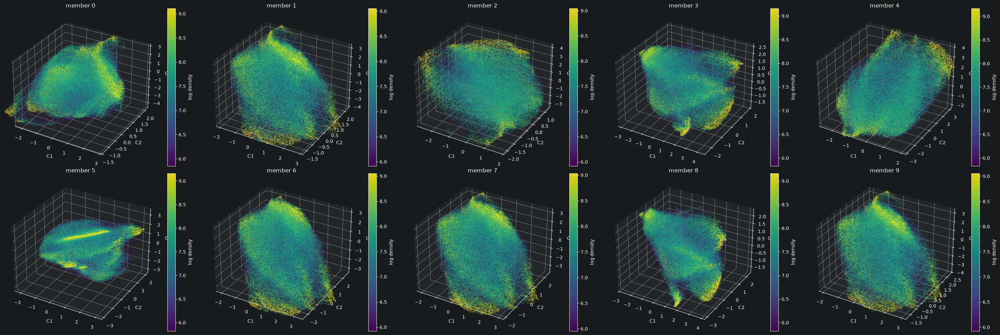

In [3]:
densities = [log_dtm(embeddings[m], rows, K_DENS) for m in range(n_members)]
densities = [np.clip(d, *np.percentile(d, (1, 99))) for d in densities]
vis_dim_redux_list(embeddings[:, rows], labels=densities, categorical=False, label_title="log density",
                   dims=dims, alpha=ALPHA, n_cols=5, titles=[f"member {m}" for m in range(n_members)])

31 clusters; 443 of 100,000 drawn fronts are noise


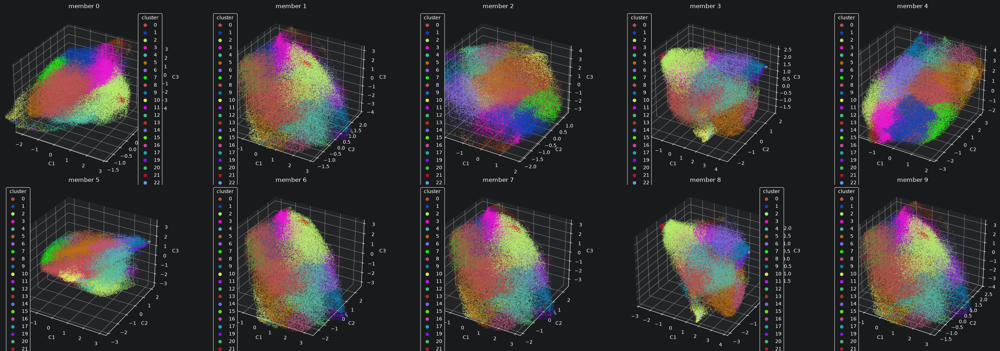

In [4]:
clusters = np.load(NEMI_FILE)["clusters"]           # consensus cluster per front, -1 where members disagreed
agreed = rows[clusters[rows] >= 0]
print(f"{np.unique(clusters[agreed]).size} clusters; {len(rows) - len(agreed):,} of {len(rows):,} drawn fronts are noise")
vis_dim_redux_list(embeddings[:, agreed], labels=clusters[agreed], label_title="cluster",
                   dims=dims, alpha=ALPHA, n_cols=5, titles=[f"member {m}" for m in range(n_members)])

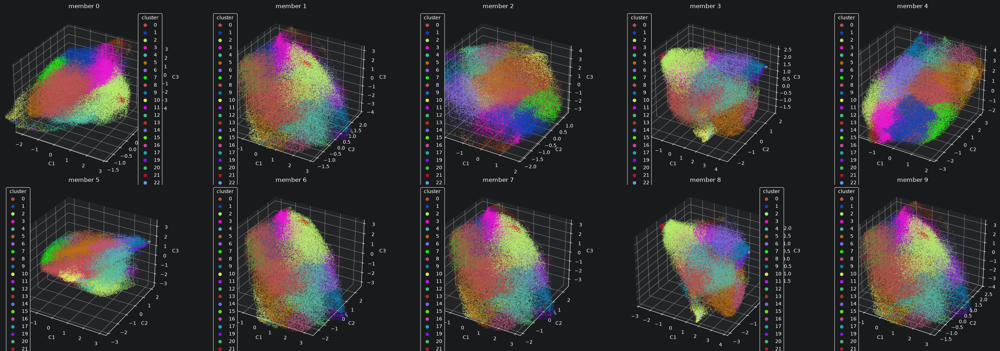

In [5]:
vis_dim_redux_list(embeddings[:, agreed], labels=clusters[agreed], label_title="cluster",
                   dims=dims, alpha=ALPHA, n_cols=5, titles=[f"member {m}" for m in range(n_members)])